# 13 把注意力、残差与归一化接成 Transformer

## 1 给字符一个可以学习的表示

上一课的注意力已经能读取一列向量。文本却由字符组成：怎样把字符交给它，又怎样把取回的信息接成下一层？这一课会把这些部件接成一个小型 Transformer。

可以先给每个字符编号，再为每个编号准备一行可训练的数。`nn.Embedding` 就是这张表。例如编号1取第1行，字符本身没有被当作数值大小参与乘法；被训练的是那一行的向量。

下面一次放入两条序列，每条有三个位置。B 表示序列条数，T 表示位置数，C 表示向量长度；于是整数编号从 `(B,T)` 变为 `(B,T,C)`。整张查找表为 `(V,C)`，V 是可用编号的总数。

In [1]:
from support import ROOT, check, show, style

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
torch.set_num_threads(1)
torch.manual_seed(7)
style()

In [3]:
tokens = torch.tensor([[0,1,2],[2,1,0]])
embedding = nn.Embedding(4,6)
embedded = embedding(tokens)
print('IDs:',tokens.shape,'权重表:',embedding.weight.shape,'向量:',embedded.shape)
check('查表等于取行',embedded[0,1],embedding.weight[1])

IDs: torch.Size([2, 3]) 权重表: torch.Size([4, 6]) 向量: torch.Size([2, 3, 6])
通过：查表等于取行


### 练习 t01：取出一个 token 的向量

从 embedded 取 batch 1、位置 2 的向量。

In [4]:
ex_t01_vector = None

In [5]:
# 填写上一格后，运行检查。
check('该位置的向量',ex_t01_vector,embedding.weight[0])

待填写：该位置的向量


<details>
<summary>提示</summary>

两个下标先选序列与位置，最后一个轴全部保留。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t01_vector = embedded[1,2]
```

</details>

## 2 位置信息与内容相加

“我喜欢你”和“你喜欢我”由同样的字组成，顺序却改变了关系。只按内容匹配的无 mask 注意力，在输入重排时也随之重排；位置还需要自己的表示。这里为位置建立另一张可学习的表 $P\in\mathbb R^{T_{\max}\times C}$。
$T_{\max}$ 是位置表允许的最大序列长度，对应模型配置的 context 上限。

位置向量形状 `(T,C)`，相加时广播到 B 条序列：$H_{b,t}=E_{\mathrm{id}_{b,t}}+P_t$。

In [6]:
positions = nn.Embedding(8,6)
position_vectors = positions(torch.arange(tokens.shape[1]))
hidden = embedded + position_vectors
print('位置表输出：',position_vectors.shape,'相加后：',hidden.shape)

位置表输出： torch.Size([3, 6]) 相加后： torch.Size([2, 3, 6])


### 练习 t02：看清广播的两个轴

取 batch 0、位置 1，自己把内容向量和位置向量相加。

In [7]:
ex_t02_hidden = None

In [8]:
# 填写上一格后，运行检查。
check('位置加内容',ex_t02_hidden,hidden[0,1])

待填写：位置加内容


<details>
<summary>提示</summary>

两个加数都应是长度为 C 的向量。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t02_hidden = embedded[0,1]+position_vectors[1]
```

</details>

## 3 先将上一课的一头装进 Module

线性投影作用于最后一个轴，前面的 B、T 都保留。缓存的三角 mask 不是要训练的参数，使用 `register_buffer`，它会跟随模型保存与迁移设备。

In [9]:
class AttentionHead(nn.Module):
    def __init__(self, width, head_size, context):
        super().__init__()
        self.query = nn.Linear(width, head_size, bias=False)
        self.key = nn.Linear(width, head_size, bias=False)
        self.value = nn.Linear(width, head_size, bias=False)
        self.register_buffer('mask', torch.tril(torch.ones(context, context)).bool())

    def forward(self, x):
        q, k, v = self.query(x), self.key(x), self.value(x)
        scores = q @ k.transpose(-2, -1) / (q.shape[-1] ** .5)
        length = x.shape[1]
        scores = scores.masked_fill(~self.mask[:length, :length], float('-inf'))
        weights = F.softmax(scores, dim=-1)
        return weights @ v

In [10]:
head = AttentionHead(width=6,head_size=3,context=8)
one_head = head(hidden)
print('一头输出：',one_head.shape)

一头输出： torch.Size([2, 3, 3])


## 4 多头让同一个位置有多套读取方式

一套 Q、K、V 只给每个位置形成一种读取结果。多头注意力给它多套独立投影，于是同一位置可以同时取得几种不同的组合；这些组合如何有用，由训练目标决定。

每头输出 `(B,T,D)`，H 头沿最后一轴拼接为 `(B,T,H×D)`，取 H×D=C。拼接保留各头的结果，随后的一次线性投影再将它们混合。

`ModuleList` 注册一组可训练子模块；普通 Python 列表不会自动完成参数注册。先显式逐头计算，后面阅读 minGPT 时再把 H 合进 batch 维。

In [11]:
class MultiHead(nn.Module):
    def __init__(self, width, heads, context):
        super().__init__()
        assert width % heads == 0
        self.heads = nn.ModuleList([AttentionHead(width, width // heads, context) for _ in range(heads)])
        self.projection = nn.Linear(width, width)

    def forward(self, x):
        pieces = [head(x) for head in self.heads]
        return self.projection(torch.cat(pieces, dim=-1))

In [12]:
multi = MultiHead(width=6,heads=2,context=8)
print('两头各自输出：',[h(hidden).shape for h in multi.heads])
print('拼接与投影后：',multi(hidden).shape)

两头各自输出： [torch.Size([2, 3, 3]), torch.Size([2, 3, 3])]
拼接与投影后： torch.Size([2, 3, 6])


### 练习 t03：两头怎样拼接

把形状相同的两个头沿特征轴拼接，保留 B 与 T。

In [13]:
ex_t03_joined = None

In [14]:
# 填写上一格后，运行检查。
check('拼接形状',None if ex_t03_joined is None else ex_t03_joined.shape,(2,3,6))
check('第一头仍保留',None if ex_t03_joined is None else ex_t03_joined[...,:3],one_head)

待填写：拼接形状
待填写：第一头仍保留


<details>
<summary>提示</summary>

`torch.cat([...],dim=-1)`。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t03_joined = torch.cat([one_head,one_head],dim=-1)
```

</details>

## 5 LayerNorm 在每个位置内部归一化

多层运算会不断改变向量的尺度。LayerNorm 在一个位置内部，把各坐标减去均值，再除以共同的标准差；随后用可学习的尺度和偏移调整输出。

对一个 C 维向量，$m=C^{-1}\sum_c x_c$，$v=C^{-1}\sum_c(x_c-m)^2$，输出 $\gamma_c(x_c-m)/\sqrt{v+\epsilon}+\beta_c$。γ、β 各有 C 项。$\epsilon$ 是防止分母为零的正小常数，这里为 $10^{-5}$。

下面只计算一个位置。方差按 C 除，`unbiased=False` 对应这一公式。

In [15]:
sample = torch.tensor([1.,2.,3.])
mean = sample.mean()
variance = ((sample-mean)**2).mean()
manual_norm = (sample-mean)/torch.sqrt(variance+1e-5)
norm = nn.LayerNorm(3)
check('手算 LayerNorm',norm(sample),manual_norm)

通过：手算 LayerNorm

### 练习 t04：给归一化增加尺度与偏移

γ 全为 2、β 全为 1，计算归一化后的向量。

In [16]:
ex_t04_affine = None

In [17]:
# 填写上一格后，运行检查。
check('尺度和偏移',ex_t04_affine,2*manual_norm+1)

待填写：尺度和偏移


<details>
<summary>提示</summary>

先用上面的 manual_norm，再逐坐标乘 γ、加 β。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t04_affine = 2*manual_norm+1
```

</details>

## 6 残差上的导数包含两条路径

注意力读出的向量作为对原表示的一次修正，加回输入：$y=x+F(x)$。于是输入可以沿直连路径继续传递，也可以经过 F 参与修正。

反向时，下游梯度分别进入两条支路，回到 x 时相加：$\partial L/\partial x=(I+J_F)^\top\partial L/\partial y$。$J_F$ 是 F 对 x 的 Jacobian。对标量 $F(x)=2x$，两条贡献为1和2，合起来是3。

[打开残差实验](../../interactive/index.html#residual)，逐步回传同一个梯度，再切换到两路抵消的例子。直连贡献存在时，总梯度仍取决于两路相加的结果。

In [18]:
residual_input = torch.tensor(2.,requires_grad=True)
residual_output = residual_input+2*residual_input
residual_output.backward()
check('两条路径的导数相加',residual_input.grad,3.)

通过：两条路径的导数相加


每个位置的前馈网络先把 C 扩成 4C，经过非线性后再投回 C。所有位置共享这组权重；位置间的信息交换发生在注意力中。

In [19]:
class FeedForward(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(width, 4 * width), nn.GELU(), nn.Linear(4 * width, width))

    def forward(self, x):
        return self.layers(x)

接成 Pre-LN 块：先归一化、做注意力、加回输入，再归一化、做前馈、加回上一状态。每次残差相加的两项形状相同。

In [20]:
class Block(nn.Module):
    def __init__(self, width, heads, context):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(width), nn.LayerNorm(width)
        self.attention, self.ff = MultiHead(width, heads, context), FeedForward(width)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        return x + self.ff(self.norm2(x))

沿图先走直连，再走下方的计算分支；每个 Σ 把两项相加。反向时，下游梯度从 Σ 同时进入两条输入路径，回到分支起点后再求和。图中的全部支路对应上面 forward 的两行更新。

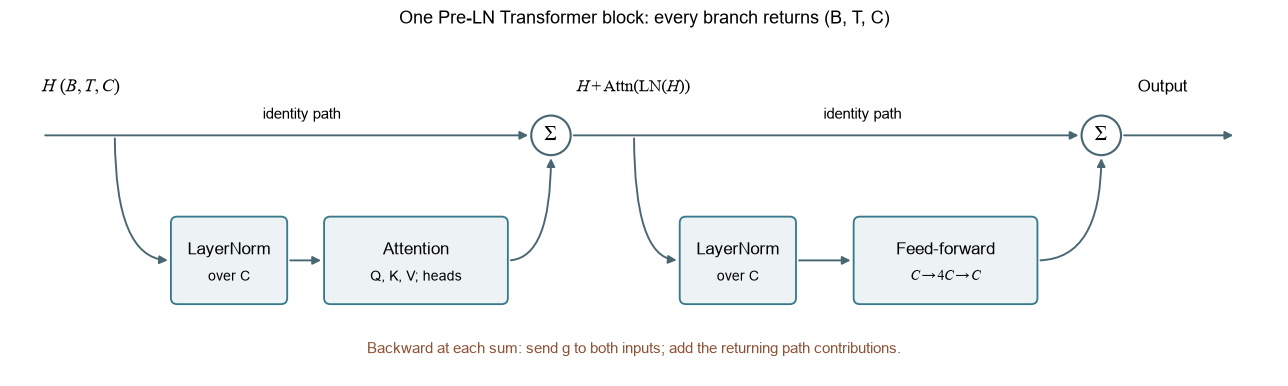

In [21]:
from support import block_diagram
show(block_diagram())

In [22]:
block = Block(width=6,heads=2,context=8)
block_output = block(hidden)
check('块保持B,T,C',block_output.shape,hidden.shape)

通过：块保持B,T,C


### 练习 t05：独立写一个残差块的 forward

已有 attention、ff、norm1、norm2，按顺序写出两次残差。

In [23]:
def ex_t05_forward(module,x):
    return None

In [24]:
# 填写上一格后，运行检查。
check('两次残差的顺序',ex_t05_forward(block,hidden),block_output)

待填写：两次残差的顺序


<details>
<summary>提示</summary>

第二次加回的是第一次更新后的 x。

</details>

<details>
<summary>参考答案</summary>

```python
def ex_t05_forward(module,x):
    x=x+module.attention(module.norm1(x))
    return x+module.ff(module.norm2(x))
```

</details>

最后堆叠若干块，接最终归一化与词表投影。每个位置输出 V 个 logits，形状 `(B,T,V)`。这里把已经写过的组件组装成完整模型。

In [25]:
class TinyGPT(nn.Module):
    def __init__(self, vocab_size, context=16, width=24, heads=2, depth=1):
        super().__init__()
        self.context = context
        self.token = nn.Embedding(vocab_size, width)
        self.position = nn.Embedding(context, width)
        self.blocks = nn.Sequential(*[Block(width, heads, context) for _ in range(depth)])
        self.norm, self.output = nn.LayerNorm(width), nn.Linear(width, vocab_size)

    def forward(self, tokens):
        length = tokens.shape[1]
        x = self.token(tokens) + self.position(torch.arange(length, device=tokens.device))
        return self.output(self.norm(self.blocks(x)))

In [26]:
model = TinyGPT(vocab_size=4,context=8,width=6,heads=2,depth=2)
logits = model(tokens)
print('最终logits：',logits.shape)
changed_tokens = tokens.clone(); changed_tokens[:, -1] = 3
check('完整模型不会读取未来token',model(changed_tokens)[:,:2],logits[:,:2])
print('参数总数：',sum(p.numel() for p in model.parameters()))

最终logits： torch.Size([2, 3, 4])
通过：完整模型不会读取未来token
参数总数： 1096


### 练习 t06：取下一 token 的预测分数

取第一条序列最后一个位置的全部词表分数。

In [27]:
ex_t06_last = None

In [28]:
# 填写上一格后，运行检查。
check('下一个token的分数',ex_t06_last,logits[0,-1])

待填写：下一个token的分数


<details>
<summary>提示</summary>

先选 batch 0，再选位置 -1；保留词表轴。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t06_last = logits[0,-1,:]
```

</details>

## 带着问题读原文

[minGPT: CausalSelfAttention 与 Block](https://github.com/karpathy/minGPT/blob/master/mingpt/model.py)

将这课的逐头实现对照其 view(B,T,H,D).transpose(1,2)。画出两个实现的形状表。独立实验：保留参数和输入，去掉位置信息并同时重排位置，先在无mask的一头上检验置换等变性。